In [14]:
import re
import pandas as pd

# Membuat DataFrame 'data' menggunakan baris-baris dari variabel 'teks'
baris_teks = [line.strip() for line in teks.split('\n') if line.strip()]
data = pd.DataFrame({'teks': baris_teks})

data['huruf_kecil'] = data['teks'].str.lower()
data['bersih'] = data['huruf_kecil'].str.replace(r'[^a-z0-9\s]', ' ', regex=True)
data['bersih'] = data['bersih'].str.replace(r'\s+', ' ', regex=True).str.strip()
data[['teks', 'bersih']].head()

,teks,bersih
0,hari kamis ada seroang wanita berjilbab warna ...,hari kamis ada seroang wanita berjilbab warna ...
1,dia seorang mahasiswa akhir prodi matematika.,dia seorang mahasiswa akhir prodi matematika
2,dia mahasiswa dengan wajah ceria dan cantik se...,dia mahasiswa dengan wajah ceria dan cantik se...


In [15]:
contoh = data.loc[0, 'bersih']
token = contoh.split()
print('Teks:', contoh)
print('Token:', token)

Teks: hari kamis ada seroang wanita berjilbab warna abu abu
Token: ['hari', 'kamis', 'ada', 'seroang', 'wanita', 'berjilbab', 'warna', 'abu', 'abu']


In [16]:
!pip install Sastrawi

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)

['hari', 'kamis', 'seroang', 'wanita', 'berjilbab', 'warna', 'abu', 'abu']


In [1]:
!pip install Sastrawi -q

import re
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# 1. Data asli
teks = """hari kamis ada seroang wanita berjilbab warna abu-abu,
dia seorang mahasiswa akhir prodi matematika.
dia mahasiswa dengan wajah ceria dan cantik sekali"""

print("DATA ASLI:")
print(teks)

DATA ASLI:
hari kamis ada seroang wanita berjilbab warna abu-abu,
dia seorang mahasiswa akhir prodi matematika.
dia mahasiswa dengan wajah ceria dan cantik sekali


In [3]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Memecah teks menjadi token kata menggunakan regex
token_penting = re.findall(r'\b\w+\b', teks.lower())

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['hari', 'kamis', 'ada', 'seroang', 'wanita', 'berjilbab', 'warna', 'abu', 'abu', 'dia', 'seorang', 'mahasiswa', 'akhir', 'prodi', 'matematika', 'dia', 'mahasiswa', 'dengan', 'wajah', 'ceria', 'dan', 'cantik', 'sekali']
Sesudah: ['hari', 'kamis', 'ada', 'seroang', 'wanita', 'jilbab', 'warna', 'abu', 'abu', 'dia', 'orang', 'mahasiswa', 'akhir', 'prodi', 'matematika', 'dia', 'mahasiswa', 'dengan', 'wajah', 'ceria', 'dan', 'cantik', 'sekali']


In [5]:
from collections import Counter
import matplotlib.pyplot as plt
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Mendapatkan daftar stopwords bahasa Indonesia
factory = StopWordRemoverFactory()
stopwords = factory.get_stop_words()

# Menggunakan kata hasil stemming yang sudah ada
semua_kata = hasil_stem

# Menghitung frekuensi kata yang bukan stopword
frekuensi = Counter(
    kata for kata in semua_kata if kata not in stopwords
)
print(frekuensi.most_common(10))

[('abu', 2), ('mahasiswa', 2), ('hari', 1), ('kamis', 1), ('seroang', 1), ('wanita', 1), ('jilbab', 1), ('warna', 1), ('orang', 1), ('akhir', 1)]


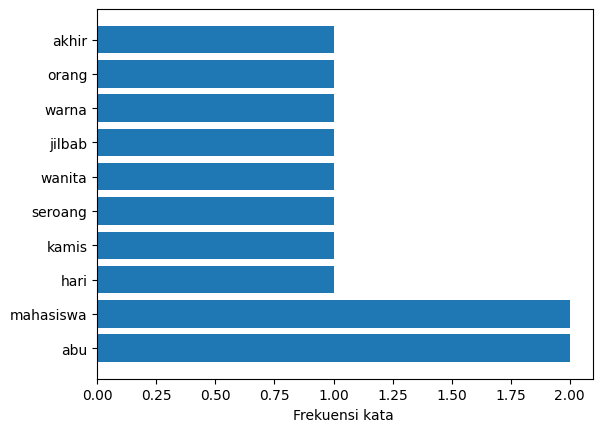

In [6]:
kata , jumlah = zip (* frekuensi . most_common (10) )
plt . barh ( kata , jumlah )
plt . xlabel ('Frekuensi kata ')
plt . show ()

In [8]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Membagi teks menjadi beberapa baris dokumen
dokumen = [line.strip() for line in teks.split('\n') if line.strip()]

count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

,abu,ada,akhir,berjilbab,cantik,ceria,dan,dengan,dia,hari,kamis,mahasiswa,matematika,prodi,sekali,seorang,seroang,wajah,wanita,warna
0,2,1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,1,0,1,1
1,0,0,1,0,0,0,0,0,1,0,0,1,1,1,0,1,0,0,0,0
2,0,0,0,0,1,1,1,1,1,0,0,1,0,0,1,0,0,1,0,0


In [12]:
from sklearn . feature_extraction . text import TfidfVectorizer
tfidf = TfidfVectorizer ()
matriks_tfidf = tfidf . fit_transform ( dokumen )
pd . DataFrame (
matriks_tfidf . toarray () ,
columns = tfidf . get_feature_names_out ()
) . round (2)

,abu,ada,akhir,berjilbab,cantik,ceria,dan,dengan,dia,hari,kamis,mahasiswa,matematika,prodi,sekali,seorang,seroang,wajah,wanita,warna
0,0.6,0.3,0.00,0.3,0.00,0.00,0.00,0.00,0.00,0.3,0.3,0.00,0.00,0.00,0.00,0.00,0.3,0.00,0.3,0.3
1,0.0,0.0,0.44,0.0,0.00,0.00,0.00,0.00,0.33,0.0,0.0,0.33,0.44,0.44,0.00,0.44,0.0,0.00,0.0,0.0
2,0.0,0.0,0.00,0.0,0.37,0.37,0.37,0.37,0.28,0.0,0.0,0.28,0.00,0.00,0.37,0.00,0.0,0.37,0.0,0.0
